In [6]:
from transformers import GPT2LMHeadModel
import torch
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass

torch.set_default_device(device='cuda')
torch.manual_seed(1234)
torch.cuda.manual_seed(1234)

In [2]:
import tiktoken

## GÖREV 1

In [9]:
class DataLoader:
    def __init__(self, batch_size, block_size, input_file):
        self.pos = 0
        self.epoch = 0
        self.batch_size = batch_size
        self.block_size = block_size
        with open(input_file, 'r') as f: self.data = f.read()
        encoder = tiktoken.get_encoding('gpt2')
        self.data = torch.tensor(encoder.encode(self.data))
    def __call__(self):
        buffer = self.data[self.pos:self.pos+(self.block_size*self.batch_size)+1]
        x = buffer[:-1].view(self.batch_size, -1)
        y = buffer[1:].view(self.batch_size, -1)
        self.pos += self.block_size * self.batch_size
        if self.pos >= self.data.shape[0]:
            self.pos = 0
            print(f"epoch {self.epoch} tamamlandi")
            self.epoch+=1
        return x,y

In [4]:
import urllib
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
urllib.request.urlretrieve(url, "shakespeare.txt")

('shakespeare.txt', <http.client.HTTPMessage at 0x7d3cab0c3250>)

In [5]:
class CausalSelfAttention(nn.Module):
    def __init__(self,config, flash_attention):
        super().__init__()
        self.flash_attention = flash_attention
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.residual = True
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size)).view(1, 1, config.block_size, config.block_size))
    def forward(self,x):
        B, T, C = x.shape
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2) 
        # n_embd x (3 * n_embd) boyutlu tek c_attn katmanini uce ayirir. boylece q,k,v matrislerinin hepsi ayri bir girdiymis gibi, batch icindeki elemanlar gibi hesaplanir.
        q = q.view(B, T, self.n_head, C//self.n_head).transpose(1,2)
        k = k.view(B, T, self.n_head, C//self.n_head).transpose(1,2) 
        v = v.view(B, T, self.n_head, C//self.n_head).transpose(1,2)
        # q,k,v'nin icindeki headler ayrilir, headler birbirlerinden izole edilerek batch dimension haline getilir. dort boyutlu tensorlar olusmus olur
        # transpoze edilmesinin sebebi de her headin ayri bir batch dimension olarak alinmasi, T yani ornekler boyutu ile C yani kanallar her head icinde bagimsiz isleme alinmalidir.
        
        if not self.flash_attention: 
            attn = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(q.size(-1)))

            attn = attn.masked_fill(
                self.bias[:, :, :T, :T] == 0,
                float('-inf')
            )

            attn = F.softmax(attn, dim=-1)
            out = attn @ v
        else:
            out = F.scaled_dot_product_attention(q,k,v,is_causal=True)
        out = out.transpose(1,2).contiguous().view(B, T, C)
        # hesaplamalar yapildiktan sonra tekrar eski haline getiriliyor
        out = self.c_proj(out)
        return out

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.residual = True
    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x
class Block(nn.Module):
    def __init__(self, config,flash_attention):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config=config, flash_attention=flash_attention)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config=config)
    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size:int = 1024
    vocab_size:int = 50257
    n_layers:int = 12
    n_head:int = 12
    n_embd:int = 768
    weight_tying:bool = True

class GPT(nn.Module):
    def __init__(self, config,flash_attention=False):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(wte = nn.Embedding(config.vocab_size, config.n_embd), wpe = nn.Embedding(config.block_size, config.n_embd), h = nn.ModuleList([Block(config, flash_attention) for _ in range(config.n_layers)]), ln_f = nn.LayerNorm(config.n_embd)))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        if config.weight_tying: self.transformer.wte.weight = self.lm_head.weight
        self.apply(self._init_weights)
    def _init_weights(self, module):
        # Residual katmanlari logitslerin asiri yukselmemesi icin scale edilir. 
        # Gecen haftanin ilk gorevinde logitsleri incelerken logitslerin sayi degerlerinin buyuk oldugunu gorebiliriz.
        # Model calisirken FP16'da sorun olusturabilir, buyuk degerler FP16'nin 2**5=32 exponent kapasitesinin gecebilir ve overflowa neden olur.
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02 if not hasattr(module, 'residual') else 0.02*(2*self.config.n_layers)**-0.5)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    @classmethod
    def from_pretrained(cls, model_type):
        configs = {
            'gpt2': dict(n_layers = 12, n_head = 12, n_embd = 768),
            'gpt2-medium': dict(n_layers = 24, n_head = 16, n_embd = 1024),
            'gpt2-large': dict(n_layers = 36, n_head = 20, n_embd = 1280), 'gpt2-xl': dict(n_layers = 48, n_head = 25, n_embd = 1600)
        }[model_type]
        configs['vocab_size'] = 50257
        configs['block_size'] = 1024
        config = GPTConfig(**configs)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = [k for k in sd.keys() if not k.endswith('.attn.masked_bias')]

        hf_model = GPT2LMHeadModel.from_pretrained(model_type)
        hf_sd = hf_model.state_dict()
        hf_sd_keys = [k for k in hf_sd.keys() if not k.endswith('.attn.masked_bias') and not k.endswith('.attn.bias') and not (k.endswith('lm_head.weight') if config.weight_tying else False)]
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']

        for k in hf_sd_keys:
            if any(k.endswith(w) for w in transposed):
                assert hf_sd[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(hf_sd[k].t())
            else:
                assert hf_sd[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(hf_sd[k])
        return model
    def forward(self, x, targets=None):
        token_embeddings = self.transformer.wte(x)
        positional_embeddings = self.transformer.wpe(torch.arange(x.shape[1],device='cuda'))
        x = token_embeddings + positional_embeddings
        for block in self.transformer['h']:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)

        if targets==None:
            return logits
        else:
            return (F.cross_entropy(logits.view(-1, logits.size(-1)),targets.view(-1)), logits) # (loss, logits) dondurulur
            # batch dimensionlari duzlestirilerek karsilastirma islemleri paralellestirilir

In [8]:
import time
import math

config = GPTConfig()
model = GPT(config)
model = model.to('cuda')
optim = torch.optim.AdamW(model.parameters(),lr=5e-4)
data_loader = DataLoader(4,1024,"shakespeare.txt")


for i in range(500):
    beginning_time = time.time()
    x,y = data_loader()
    x,y = x.to('cuda'), y.to('cuda')
    optim.zero_grad()
    loss, logits = model(x,y)
    loss.backward()
    optim.step()
    print(f"loss {loss.item()}")

loss 11.106246948242188
loss 9.519035339355469
loss 9.034482955932617
loss 8.590392112731934
loss 8.192517280578613
loss 7.690736770629883
loss 7.431931495666504
loss 7.15969181060791
loss 7.052540302276611
loss 6.7619829177856445


KeyboardInterrupt: 

Weight tying'den sonra parametre sayisi

In [9]:
param_count = sum(p.numel() for p in model.parameters())
param_count

124439808

## GÖREV 2

| Eğitim döngüsü | token/sn |
|-------|------|
| torch.compile (FP32)     | 3321 |
| torch.compile + vocab size yuvarlandı  (FP32)      | 3194 |
| torch.compile + flash attention + vocab size yuvarlandı (FP32)      | 4082 |
| torch.compile (FP16)     | 15320 |

# Model derlendi, FP16

In [11]:
import time


config = GPTConfig()
model = GPT(config, flash_attention=True)
model = model.to('cuda')
model = torch.compile(model)
optim = torch.optim.AdamW(model.parameters(),lr=5e-4)
data_loader = DataLoader(4,1024,"shakespeare.txt")


for i in range(500):
    beginning_time = time.time()
    x,y = data_loader()
    x,y = x.to('cuda'), y.to('cuda')
    with torch.autocast('cuda', torch.float16):
        loss, logits = model(x,y)
    optim.zero_grad()
    loss.backward()
    optim.step()
    torch.cuda.synchronize()
    end_time = time.time()
    time_spent = (end_time-beginning_time)*1000
    tps = (data_loader.block_size*data_loader.batch_size/time_spent)*1000
    print(f"{tps:.1f} token/s - {time_spent:.3f}/step - loss {loss.item()}")

926.7 token/s - 4420.071/step - loss 10.889461517333984
15320.0 token/s - 267.364/step - loss 9.582853317260742
15190.9 token/s - 269.635/step - loss 9.109638214111328
15022.7 token/s - 272.654/step - loss 8.888656616210938
15142.1 token/s - 270.504/step - loss 8.570686340332031
15035.6 token/s - 272.420/step - loss 8.243827819824219
15238.3 token/s - 268.796/step - loss 8.18742561340332
15241.4 token/s - 268.742/step - loss 8.007892608642578
15312.1 token/s - 267.500/step - loss 7.951900959014893
15094.2 token/s - 271.362/step - loss 7.719747543334961
14949.2 token/s - 273.994/step - loss 7.708120346069336
15180.5 token/s - 269.819/step - loss 7.693554878234863
15031.5 token/s - 272.495/step - loss 7.757219314575195
15208.0 token/s - 269.332/step - loss 7.679530143737793
15204.9 token/s - 269.387/step - loss 7.301841735839844
15002.7 token/s - 273.018/step - loss 7.263972282409668
15197.5 token/s - 269.518/step - loss 7.051219940185547
15217.1 token/s - 269.170/step - loss 6.886245727

KeyboardInterrupt: 

# Model derlendi, FP32

In [10]:
import time


config = GPTConfig()
model = GPT(config)
model = model.to('cuda')
model = torch.compile(model)
optim = torch.optim.AdamW(model.parameters(),lr=5e-4)
data_loader = DataLoader(4,1024,"shakespeare.txt")


for i in range(500):
    beginning_time = time.time()
    x,y = data_loader()
    x,y = x.to('cuda'), y.to('cuda')
    loss, logits = model(x,y)
    optim.zero_grad()
    loss.backward()
    optim.step()
    torch.cuda.synchronize()
    end_time = time.time()
    time_spent = (end_time-beginning_time)*1000
    tps = (data_loader.block_size*data_loader.batch_size/time_spent)*1000
    print(f"{tps:.1f} token/s - {time_spent:.3f}/step - loss {loss.item()} - norm {torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)}")

3321.8 token/s - 1233.058/step - loss 10.98853874206543 - norm 32.77016830444336
3512.4 token/s - 1166.169/step - loss 9.418864250183105 - norm 4.921952724456787
3486.3 token/s - 1174.882/step - loss 8.804547309875488 - norm 2.1491456031799316
3487.1 token/s - 1174.606/step - loss 8.444661140441895 - norm 3.034615993499756
3492.6 token/s - 1172.777/step - loss 7.997208595275879 - norm 2.328779697418213
3472.0 token/s - 1179.720/step - loss 7.508128643035889 - norm 1.9075406789779663
3495.0 token/s - 1171.947/step - loss 7.288641929626465 - norm 1.9026579856872559


KeyboardInterrupt: 

# Model derlendi, FP32, vocab size yuvarlandi

In [12]:
import time


config = GPTConfig(vocab_size=50304)
model = GPT(config)
model = model.to('cuda')
model = torch.compile(model)
optim = torch.optim.AdamW(model.parameters(),lr=5e-4)
data_loader = DataLoader(4,1024,"shakespeare.txt")


for i in range(500):
    beginning_time = time.time()
    x,y = data_loader()
    x,y = x.to('cuda'), y.to('cuda')
    loss, logits = model(x,y)
    optim.zero_grad()
    loss.backward()
    optim.step()
    torch.cuda.synchronize()
    end_time = time.time()
    time_spent = (end_time-beginning_time)*1000
    tps = (data_loader.block_size*data_loader.batch_size/time_spent)*1000
    print(f"{tps:.1f} token/s - {time_spent:.3f}/step - loss {loss.item()}")

3194.9 token/s - 1282.045/step - loss 10.904998779296875
3448.1 token/s - 1187.891/step - loss 9.47459602355957
3445.9 token/s - 1188.672/step - loss 8.80439567565918
3468.8 token/s - 1180.820/step - loss 8.405366897583008
3448.2 token/s - 1187.872/step - loss 7.948254108428955
3447.1 token/s - 1188.245/step - loss 7.42995548248291
3435.7 token/s - 1192.172/step - loss 7.255500793457031


KeyboardInterrupt: 

## Model derlendi, flash attention eklendi, vocab size yuvarlandi, FP32

In [13]:
import time


config = GPTConfig(vocab_size=50304)
model = GPT(config, flash_attention=True)
model = model.to('cuda')
model = torch.compile(model)
optim = torch.optim.AdamW(model.parameters(),lr=5e-4)
data_loader = DataLoader(4,1024,"shakespeare.txt")


for i in range(500):
    beginning_time = time.time()
    x,y = data_loader()
    x,y = x.to('cuda'), y.to('cuda')
    loss, logits = model(x,y)
    optim.zero_grad()
    loss.backward()
    optim.step()
    torch.cuda.synchronize()
    end_time = time.time()
    time_spent = (end_time-beginning_time)*1000
    tps = (data_loader.block_size*data_loader.batch_size/time_spent)*1000
    print(f"{tps:.1f} token/s - {time_spent:.3f}/step - loss {loss.item()}")

2642.4 token/s - 1550.104/step - loss 11.043329238891602
4082.0 token/s - 1003.431/step - loss 9.511579513549805
4089.5 token/s - 1001.579/step - loss 8.893404006958008
4051.7 token/s - 1010.942/step - loss 8.632678031921387
4065.1 token/s - 1007.601/step - loss 8.046321868896484
4060.5 token/s - 1008.741/step - loss 7.64805793762207
4082.3 token/s - 1003.350/step - loss 7.406001091003418


KeyboardInterrupt: 

## GÖREV 3

In [5]:
import math
max_lr = 6e-4
min_lr = max_lr*0.1
warmup = 10
max_steps = 50
def get_lr(i):
    if i<warmup:
        return i*(max_lr/warmup)
    elif i>=max_steps:
        return min_lr
    else: return 0.5*(max_lr-min_lr)*(1+math.cos(math.pi*(i/max_steps)))+min_lr



In [7]:
class CausalSelfAttention(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.residual = True
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size)).view(1, 1, config.block_size, config.block_size))
    def forward(self,x):
        B, T, C = x.shape
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2) 
        # n_embd x (3 * n_embd) boyutlu tek c_attn katmanini uce ayirir. boylece q,k,v matrislerinin hepsi ayri bir girdiymis gibi, batch icindeki elemanlar gibi hesaplanir.
        q = q.view(B, T, self.n_head, C//self.n_head).transpose(1,2)
        k = k.view(B, T, self.n_head, C//self.n_head).transpose(1,2) 
        v = v.view(B, T, self.n_head, C//self.n_head).transpose(1,2)
        # q,k,v'nin icindeki headler ayrilir, headler birbirlerinden izole edilerek batch dimension haline getilir. dort boyutlu tensorlar olusmus olur
        # transpoze edilmesinin sebebi de her headin ayri bir batch dimension olarak alinmasi, T yani ornekler boyutu ile C yani kanallar her head icinde bagimsiz isleme alinmalidir.
        attn = q @ k.transpose(-2,-1)
        attn = attn * torch.sqrt(torch.tensor(self.n_embd//self.n_head))**-1
        attn = attn.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        attn = F.softmax(attn, dim=-1)
        out = attn @ v
        out = out.transpose(1,2).contiguous().view(B, T, C)
        # hesaplamalar yapildiktan sonra tekrar eski haline getiriliyor
        out = self.c_proj(out)
        return out

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.residual = True
    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config=config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config=config)
    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size:int = 1024
    vocab_size:int = 50257
    n_layers:int = 12
    n_head:int = 12
    n_embd:int = 768
    weight_tying:bool = True

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(wte = nn.Embedding(config.vocab_size, config.n_embd), wpe = nn.Embedding(config.block_size, config.n_embd), h = nn.ModuleList([Block(config) for _ in range(config.n_layers)]), ln_f = nn.LayerNorm(config.n_embd)))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        if config.weight_tying: self.transformer.wte.weight = self.lm_head.weight
        self.apply(self._init_weights)
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02 if not hasattr(module, 'residual') else 0.02*(2*self.config.n_layers)**-0.5)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    def configure_optimizer(self, decay, lr):
        params = {pn: p for pn,p in self.named_parameters()}
        params = {pn: p for pn,p in params.items() if p.requires_grad}
        decayed = [p for _,p in params.items() if p.dim() >= 2]
        not_decayed = [p for _,p in params.items() if p.dim() < 2]
        optim_groups = [
            {"params": decayed, 'weight_decay': decay},
            {"params": not_decayed, 'weight_decay': 0.0}
        ]
        decay_params_count = sum(p.numel() for p in decayed)
        no_decay_params_count = sum(p.numel() for p in not_decayed)
        print(f"decay uygulanan parametre sayisi: {decay_params_count} - decay uygulanmayan parametre sayisi: {no_decay_params_count}")
        optimizer = torch.optim.AdamW(optim_groups, lr=lr, betas=(.9,.95), eps=1e-8)
        return optimizer
    @classmethod
    def from_pretrained(cls, model_type):
        configs = {
            'gpt2': dict(n_layers = 12, n_head = 12, n_embd = 768),
            'gpt2-medium': dict(n_layers = 24, n_head = 16, n_embd = 1024),
            'gpt2-large': dict(n_layers = 36, n_head = 20, n_embd = 1280), 'gpt2-xl': dict(n_layers = 48, n_head = 25, n_embd = 1600)
        }[model_type]
        configs['vocab_size'] = 50257
        configs['block_size'] = 1024
        config = GPTConfig(**configs)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = [k for k in sd.keys() if not k.endswith('.attn.masked_bias')]

        hf_model = GPT2LMHeadModel.from_pretrained(model_type)
        hf_sd = hf_model.state_dict()
        hf_sd_keys = [k for k in hf_sd.keys() if not k.endswith('.attn.masked_bias') and not k.endswith('.attn.bias') and not (k.endswith('lm_head.weight') if config.weight_tying else False)]
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']

        for k in hf_sd_keys:
            if any(k.endswith(w) for w in transposed):
                assert hf_sd[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(hf_sd[k].t())
            else:
                assert hf_sd[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(hf_sd[k])
        return model
    def forward(self, x, targets=None):
        token_embeddings = self.transformer.wte(x)
        positional_embeddings = self.transformer.wpe(torch.arange(x.shape[1],device='cuda'))
        x = token_embeddings + positional_embeddings
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)

        if targets==None:
            return logits
        else:
            return (F.cross_entropy(logits.view(-1, logits.size(-1)),targets.view(-1)), logits) # (loss, logits) dondurulur
            # batch dimensionlari duzlestirilerek karsilastirma islemleri paralellestirilir

In [ ]:
import time
import tiktoken

config = GPTConfig(vocab_size=50304)
model = GPT(config)
model = model.to('cuda')
max_steps = 50
data_loader = DataLoader(4,1024,"shakespeare.txt")
optim=model.configure_optimizer(decay=0.1, lr=6e-4)
target_batch_size = 2**19
accum_steps = target_batch_size//(data_loader.batch_size*data_loader.block_size)
optim.zero_grad()
for i in range(max_steps):
    beginning_time = time.time()
    for micro_step in range(accum_steps):
        x,y = data_loader()
        x,y = x.to('cuda'), y.to('cuda')
        with torch.autocast('cuda', dtype=torch.float16):
            loss, logits = model(x,y)
            loss = loss/accum_steps
        loss.backward()

    lr = get_lr(i)
    for param_group in optim.param_groups:
        param_group['lr'] = lr
    optim.step()
    torch.cuda.synchronize()
    end_time = time.time()
    time_spent = (end_time-beginning_time)*1000
    tps = (data_loader.block_size*data_loader.batch_size/time_spent)*1000
    print(f"{tps:.1f} token/s - {time_spent:.3f}/step - loss {loss.item()} - norm {torch.nn.utils.clip_grad_norm_(model.parameters(),1)}")

decay uygulanan parametre sayisi: 124354560 - decay uygulanmayan parametre sayisi: 121344
128
epoch 0 tamamlandi
80.2 token/s - 51050.325/step - loss 0.08682604134082794 - norm 8.064306259155273
epoch 1 tamamlandi


KeyboardInterrupt: 

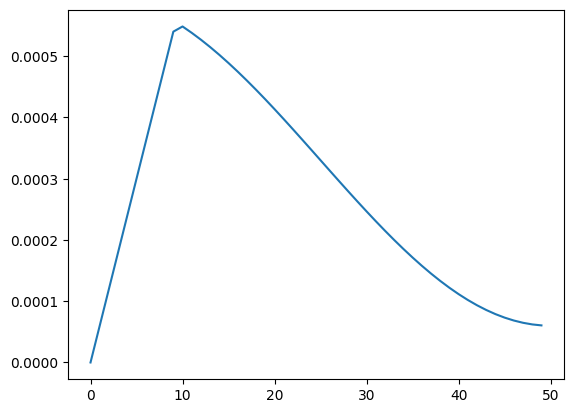

In [36]:
import matplotlib.pyplot as plt
plt.plot([get_lr(a) for a in range(50)])